# House Prices — Part C: Models

In this notebook I train and compare regression models on the data prepared in `01_EDA.ipynb`,
tune the best ones, analyse their errors and create the Kaggle submission.

## C1. Baseline and cross-validation

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_colwidth", None)

processed_dir = Path("../data/processed")
results_dir = Path("../results")
figures_dir = results_dir / "figures"
submissions_dir = Path("../submissions")

train_processed = pd.read_csv(processed_dir / "train_processed.csv")
test_processed = pd.read_csv(processed_dir / "test_processed.csv")

print("Train:", train_processed.shape)
print("Test:", test_processed.shape)

Train: (1460, 305)
Test: (1459, 304)


In [2]:
X_train = train_processed.drop(columns=["Id", "SalePrice"])
y_train = np.log1p(train_processed["SalePrice"])

X_test = test_processed.drop(columns=["Id"])
test_ids = test_processed["Id"]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)

X_train: (1460, 303)
y_train: (1460,)
X_test: (1459, 303)


All models are evaluated with the **same 5 folds** (`KFold`, `shuffle=True`, `random_state=42`), so the
comparison is fair. Each fold is used once as validation data while the model is trained on the other 4 folds.

In [3]:
from sklearn.model_selection import KFold

cv = KFold(n_splits=5, shuffle=True, random_state=42)

for fold, (train_idx, val_idx) in enumerate(cv.split(X_train), start=1):
    print(f"Fold {fold}: train = {len(train_idx)}, validation = {len(val_idx)}")

Fold 1: train = 1168, validation = 292
Fold 2: train = 1168, validation = 292
Fold 3: train = 1168, validation = 292
Fold 4: train = 1168, validation = 292
Fold 5: train = 1168, validation = 292


Every model is evaluated with the same loop over the 5 folds. In each fold the model is trained **only on the
training part** and predicts the validation part, and I save the RMSE of that fold.
For linear models the `StandardScaler` is inside a pipeline, so it is also fitted only on the training part of
each fold (no data leakage).

In [4]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import root_mean_squared_error

baseline_errors = []

for train_idx, val_idx in cv.split(X_train):
    baseline = DummyRegressor(strategy="mean")
    baseline.fit(X_train.iloc[train_idx], y_train.iloc[train_idx])

    predictions = baseline.predict(X_train.iloc[val_idx])
    rmse = root_mean_squared_error(y_train.iloc[val_idx], predictions)
    baseline_errors.append(rmse)

baseline_rmse = np.array(baseline_errors)

print("Baseline RMSE per fold:", baseline_rmse.round(4))
print(f"Mean baseline RMSE: {baseline_rmse.mean():.4f}")

Baseline RMSE per fold: [0.4332 0.3958 0.3754 0.421  0.3685]
Mean baseline RMSE: 0.3988


The baseline always predicts the mean log price of the training folds. Its RMSE is **0.3988**, which means
a typical error of about 40–50% of the price. Every real model must be much better than this.

## C2. Train and compare models

I train five models with default or simple settings:
- **Linear Regression** — the simplest linear model;
- **Ridge** — linear regression with an L2 penalty that shrinks the coefficients;
- **Lasso** — linear regression with an L1 penalty that can set coefficients exactly to 0 (feature selection);
- **Random Forest** — average of many deep decision trees trained on bootstrap samples;
- **Gradient Boosting** — small trees added one after another, each correcting the errors of the previous ones.

In [5]:
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

linear_errors = []

for train_idx, val_idx in cv.split(X_train):
    linear = make_pipeline(StandardScaler(), LinearRegression())
    linear.fit(X_train.iloc[train_idx], y_train.iloc[train_idx])

    predictions = linear.predict(X_train.iloc[val_idx])
    rmse = root_mean_squared_error(y_train.iloc[val_idx], predictions)
    linear_errors.append(rmse)

linear_rmse = np.array(linear_errors)

print("Linear Regression RMSE per fold:", linear_rmse.round(4))
print(f"Mean Linear Regression RMSE: {linear_rmse.mean():.4f}")
print(f"Mean baseline RMSE: {baseline_rmse.mean():.4f}")

Linear Regression RMSE per fold: [0.1306 0.1247 0.2266 0.154  0.112 ]
Mean Linear Regression RMSE: 0.1496
Mean baseline RMSE: 0.3988


In [6]:
ridge_errors = []

for train_idx, val_idx in cv.split(X_train):
    ridge = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
    ridge.fit(X_train.iloc[train_idx], y_train.iloc[train_idx])

    predictions = ridge.predict(X_train.iloc[val_idx])
    rmse = root_mean_squared_error(y_train.iloc[val_idx], predictions)
    ridge_errors.append(rmse)

ridge_rmse = np.array(ridge_errors)

print("Ridge RMSE per fold:", ridge_rmse.round(4))
print(f"Mean Ridge RMSE: {ridge_rmse.mean():.4f}")
print(f"Mean baseline RMSE: {baseline_rmse.mean():.4f}")

Ridge RMSE per fold: [0.1253 0.1241 0.2295 0.1538 0.1119]
Mean Ridge RMSE: 0.1489
Mean baseline RMSE: 0.3988


In [7]:
lasso_errors = []

for train_idx, val_idx in cv.split(X_train):
    lasso = make_pipeline(StandardScaler(), Lasso(alpha=0.001, max_iter=50000))
    lasso.fit(X_train.iloc[train_idx], y_train.iloc[train_idx])

    predictions = lasso.predict(X_train.iloc[val_idx])
    rmse = root_mean_squared_error(y_train.iloc[val_idx], predictions)
    lasso_errors.append(rmse)

lasso_rmse = np.array(lasso_errors)

print("Lasso RMSE per fold:", lasso_rmse.round(4))
print(f"Mean Lasso RMSE: {lasso_rmse.mean():.4f}")
print(f"Mean baseline RMSE: {baseline_rmse.mean():.4f}")

Lasso RMSE per fold: [0.1228 0.1165 0.234  0.1495 0.1061]
Mean Lasso RMSE: 0.1458
Mean baseline RMSE: 0.3988


In [8]:
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor

forest_errors = []

for train_idx, val_idx in cv.split(X_train):
    forest = RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1)
    forest.fit(X_train.iloc[train_idx], y_train.iloc[train_idx])

    predictions = forest.predict(X_train.iloc[val_idx])
    rmse = root_mean_squared_error(y_train.iloc[val_idx], predictions)
    forest_errors.append(rmse)

forest_rmse = np.array(forest_errors)

print("Random Forest RMSE per fold:", forest_rmse.round(4))
print(f"Mean Random Forest RMSE: {forest_rmse.mean():.4f}")
print(f"Mean baseline RMSE: {baseline_rmse.mean():.4f}")

Random Forest RMSE per fold: [0.1461 0.1271 0.1768 0.1471 0.1232]
Mean Random Forest RMSE: 0.1441
Mean baseline RMSE: 0.3988


In [9]:
boosting_errors = []

for train_idx, val_idx in cv.split(X_train):
    boosting = GradientBoostingRegressor(random_state=42)
    boosting.fit(X_train.iloc[train_idx], y_train.iloc[train_idx])

    predictions = boosting.predict(X_train.iloc[val_idx])
    rmse = root_mean_squared_error(y_train.iloc[val_idx], predictions)
    boosting_errors.append(rmse)

boosting_rmse = np.array(boosting_errors)

print("Gradient Boosting RMSE per fold:", boosting_rmse.round(4))
print(f"Mean Gradient Boosting RMSE: {boosting_rmse.mean():.4f}")
print(f"Mean baseline RMSE: {baseline_rmse.mean():.4f}")

Gradient Boosting RMSE per fold: [0.1327 0.1104 0.1703 0.1375 0.1154]
Mean Gradient Boosting RMSE: 0.1332
Mean baseline RMSE: 0.3988


In [10]:
initial_results = pd.DataFrame({
    "model": ["Baseline", "Linear Regression", "Ridge", "Lasso", "Random Forest", "Gradient Boosting"],
    "cv_rmse": [baseline_rmse.mean(), linear_rmse.mean(), ridge_rmse.mean(), lasso_rmse.mean(),
                forest_rmse.mean(), boosting_rmse.mean()],
    "cv_std": [baseline_rmse.std(), linear_rmse.std(), ridge_rmse.std(), lasso_rmse.std(),
               forest_rmse.std(), boosting_rmse.std()],
})

initial_results.sort_values("cv_rmse").round(4)

,model,cv_rmse,cv_std
5,Gradient Boosting,0.1332,0.0211
4,Random Forest,0.1441,0.0190
3,Lasso,0.1458,0.0464
2,Ridge,0.1489,0.0426
1,Linear Regression,0.1496,0.0408
0,Baseline,0.3988,0.0251


- All models are about 3 times better than the baseline.
- **Gradient Boosting** is the best initial model (0.1332). Each new tree corrects the errors of the previous trees,
  and the trees are not much affected by a few extreme houses.
- The three linear models are close (Lasso 0.1458, Ridge 0.1489, Linear Regression 0.1496), but they have the largest
  differences between folds (std ≈ 0.04). In fold 3 their RMSE is about 0.23, almost 2 times higher than in the other
  folds. Fold 3 contains the two very large but cheap houses (Id 524 and 1299, more than 4,500 sq ft), and the linear
  models predict a very high price for them.
- Random Forest (0.1441) is a bit better than the linear models on average and is the most stable model between folds
  (std 0.019), but it is worse than Gradient Boosting.

## C3. Hyperparameter tuning

I tune Ridge and Lasso with simple `for` loops over `alpha`, using the same 5 folds. For every value the model is
trained and scored in each fold, and I keep the value with the lowest mean RMSE. The scaler is inside the pipeline,
so it is refitted in every fold.

Gradient Boosting has three parameters (12 combinations), so I tune it with `GridSearchCV` on the same 5 folds.
`GridSearchCV` does the same loop automatically: it trains the model for every combination in every fold and keeps
the combination with the lowest mean RMSE.

Note: the best parameters are chosen and scored on the same folds, so the tuned scores are slightly optimistic.

In [11]:
ridge_results = []

for alpha in [1, 10, 30, 100, 200, 300, 500, 1000, 2000]:
    fold_errors = []

    for train_idx, val_idx in cv.split(X_train):
        ridge = make_pipeline(StandardScaler(), Ridge(alpha=alpha))
        ridge.fit(X_train.iloc[train_idx], y_train.iloc[train_idx])

        predictions = ridge.predict(X_train.iloc[val_idx])
        rmse = root_mean_squared_error(y_train.iloc[val_idx], predictions)
        fold_errors.append(rmse)

    ridge_results.append((alpha, np.array(fold_errors)))
    print(f"alpha={alpha}: mean RMSE={np.mean(fold_errors):.4f}")

best_ridge_alpha, best_ridge_rmse = min(ridge_results, key=lambda result: result[1].mean())

print("Best alpha:", best_ridge_alpha)
print("Ridge (tuned) RMSE per fold:", best_ridge_rmse.round(4))
print(f"Mean Ridge (tuned) RMSE: {best_ridge_rmse.mean():.4f}")

alpha=1: mean RMSE=0.1489
alpha=10: mean RMSE=0.1489


alpha=30: mean RMSE=0.1475


alpha=100: mean RMSE=0.1450
alpha=200: mean RMSE=0.1436


alpha=300: mean RMSE=0.1431


alpha=500: mean RMSE=0.1432
alpha=1000: mean RMSE=0.1456


alpha=2000: mean RMSE=0.1524
Best alpha: 300
Ridge (tuned) RMSE per fold: [0.1303 0.1249 0.2076 0.1403 0.1126]
Mean Ridge (tuned) RMSE: 0.1431


In [12]:
lasso_results = []

for alpha in [0.0001, 0.0005, 0.001, 0.002, 0.003, 0.005, 0.01, 0.02]:
    fold_errors = []

    for train_idx, val_idx in cv.split(X_train):
        lasso = make_pipeline(StandardScaler(), Lasso(alpha=alpha, max_iter=50000))
        lasso.fit(X_train.iloc[train_idx], y_train.iloc[train_idx])

        predictions = lasso.predict(X_train.iloc[val_idx])
        rmse = root_mean_squared_error(y_train.iloc[val_idx], predictions)
        fold_errors.append(rmse)

    lasso_results.append((alpha, np.array(fold_errors)))
    print(f"alpha={alpha}: mean RMSE={np.mean(fold_errors):.4f}")

best_lasso_alpha, best_lasso_rmse = min(lasso_results, key=lambda result: result[1].mean())

print("Best alpha:", best_lasso_alpha)
print("Lasso (tuned) RMSE per fold:", best_lasso_rmse.round(4))
print(f"Mean Lasso (tuned) RMSE: {best_lasso_rmse.mean():.4f}")

alpha=0.0001: mean RMSE=0.1484


alpha=0.0005: mean RMSE=0.1471


alpha=0.001: mean RMSE=0.1458
alpha=0.002: mean RMSE=0.1445


alpha=0.003: mean RMSE=0.1438
alpha=0.005: mean RMSE=0.1434


alpha=0.01: mean RMSE=0.1453
alpha=0.02: mean RMSE=0.1568
Best alpha: 0.005
Lasso (tuned) RMSE per fold: [0.1256 0.1137 0.23   0.1419 0.1061]
Mean Lasso (tuned) RMSE: 0.1434


In [13]:
from sklearn.model_selection import GridSearchCV

boosting_search = GridSearchCV(
    estimator=GradientBoostingRegressor(subsample=0.8, random_state=42),
    param_grid={
        "n_estimators": [300, 1000],
        "learning_rate": [0.03, 0.1],
        "max_depth": [2, 3, 4],
    },
    cv=cv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
)

boosting_search.fit(X_train, y_train)

best_n_estimators = boosting_search.best_params_["n_estimators"]
best_learning_rate = boosting_search.best_params_["learning_rate"]
best_max_depth = boosting_search.best_params_["max_depth"]

best = boosting_search.best_index_
best_boosting_rmse = np.array([-boosting_search.cv_results_[f"split{fold}_test_score"][best] for fold in range(5)])

print("Best parameters:", boosting_search.best_params_)
print("Gradient Boosting (tuned) RMSE per fold:", best_boosting_rmse.round(4))
print(f"Mean Gradient Boosting (tuned) RMSE: {best_boosting_rmse.mean():.4f}")

Best parameters: {'learning_rate': 0.03, 'max_depth': 4, 'n_estimators': 1000}
Gradient Boosting (tuned) RMSE per fold: [0.1303 0.1075 0.1653 0.1253 0.105 ]
Mean Gradient Boosting (tuned) RMSE: 0.1267


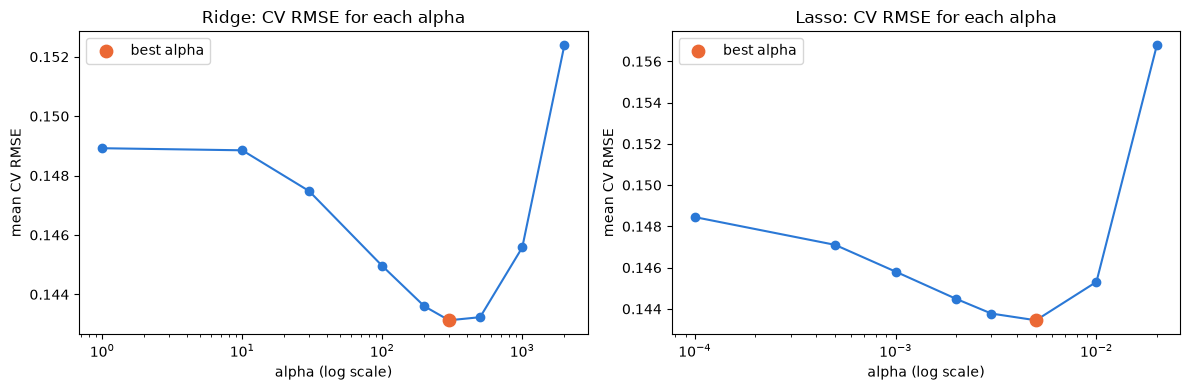

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, name, alpha_results, best_alpha in [
    (axes[0], "Ridge", ridge_results, best_ridge_alpha),
    (axes[1], "Lasso", lasso_results, best_lasso_alpha),
]:
    alphas = [alpha for alpha, fold_errors in alpha_results]
    mean_rmse = [fold_errors.mean() for alpha, fold_errors in alpha_results]

    ax.plot(alphas, mean_rmse, marker="o", color="#2a78d6")
    ax.scatter(best_alpha, min(mean_rmse), s=80, color="#eb6834", zorder=3, label="best alpha")
    ax.set_xscale("log")
    ax.set_title(f"{name}: CV RMSE for each alpha")
    ax.set_xlabel("alpha (log scale)")
    ax.set_ylabel("mean CV RMSE")
    ax.legend()

plt.tight_layout()
fig.savefig(figures_dir / "07_regularization_tuning.png", dpi=120)
plt.show()

- **Ridge:** a much stronger penalty than the default is best (`alpha=300`): 0.1489 → 0.1431.
- **Lasso:** best `alpha=0.005`: 0.1458 → 0.1434.
- **Gradient Boosting:** more trees with a smaller learning rate (`n_estimators=1000`, `learning_rate=0.03`,
  `max_depth=4`): 0.1332 → **0.1267**. `max_depth=3` gives almost the same score (0.1267).

The curves show the usual U shape: a small `alpha` overfits (the model follows noise), a large `alpha` underfits
(the coefficients are shrunk too much). The best alphas are inside the grid, not at its edge. For Gradient Boosting
the best values are at the edge of the grid (1000 trees, depth 4), so more trees could improve it a little more.

## C4. Model comparison

In [15]:
boosting_params = f"n_estimators={best_n_estimators}, learning_rate={best_learning_rate}, max_depth={best_max_depth}"

comparison = pd.DataFrame([
    {"model": "Baseline", "stage": "mean price", "fold_rmse": baseline_rmse, "params": "-"},
    {"model": "Linear Regression", "stage": "initial", "fold_rmse": linear_rmse, "params": "-"},
    {"model": "Ridge", "stage": "initial", "fold_rmse": ridge_rmse, "params": "alpha=1"},
    {"model": "Lasso", "stage": "initial", "fold_rmse": lasso_rmse, "params": "alpha=0.001"},
    {"model": "Random Forest", "stage": "initial", "fold_rmse": forest_rmse, "params": "n_estimators=300"},
    {"model": "Gradient Boosting", "stage": "initial", "fold_rmse": boosting_rmse,
     "params": "n_estimators=100, learning_rate=0.1, max_depth=3"},
    {"model": "Ridge", "stage": "tuned", "fold_rmse": best_ridge_rmse, "params": f"alpha={best_ridge_alpha}"},
    {"model": "Lasso", "stage": "tuned", "fold_rmse": best_lasso_rmse, "params": f"alpha={best_lasso_alpha}"},
    {"model": "Gradient Boosting", "stage": "tuned", "fold_rmse": best_boosting_rmse, "params": boosting_params},
])

comparison["cv_rmse"] = comparison["fold_rmse"].apply(np.mean)
comparison["cv_std"] = comparison["fold_rmse"].apply(np.std)
comparison = comparison.drop(columns="fold_rmse")[["model", "stage", "cv_rmse", "cv_std", "params"]]

comparison = comparison.sort_values("cv_rmse").reset_index(drop=True)
comparison.index = comparison.index + 1

comparison.round(4).to_csv(results_dir / "model_comparison.csv", index_label="rank")
comparison.round(4)

,model,stage,cv_rmse,cv_std,params
1,Gradient Boosting,tuned,0.1267,0.0217,"n_estimators=1000, learning_rate=0.03, max_depth=4"
2,Gradient Boosting,initial,0.1332,0.0211,"n_estimators=100, learning_rate=0.1, max_depth=3"
3,Ridge,tuned,0.1431,0.0335,alpha=300
4,Lasso,tuned,0.1434,0.0449,alpha=0.005
5,Random Forest,initial,0.1441,0.0190,n_estimators=300
6,Lasso,initial,0.1458,0.0464,alpha=0.001
7,Ridge,initial,0.1489,0.0426,alpha=1
8,Linear Regression,initial,0.1496,0.0408,-
9,Baseline,mean price,0.3988,0.0251,-


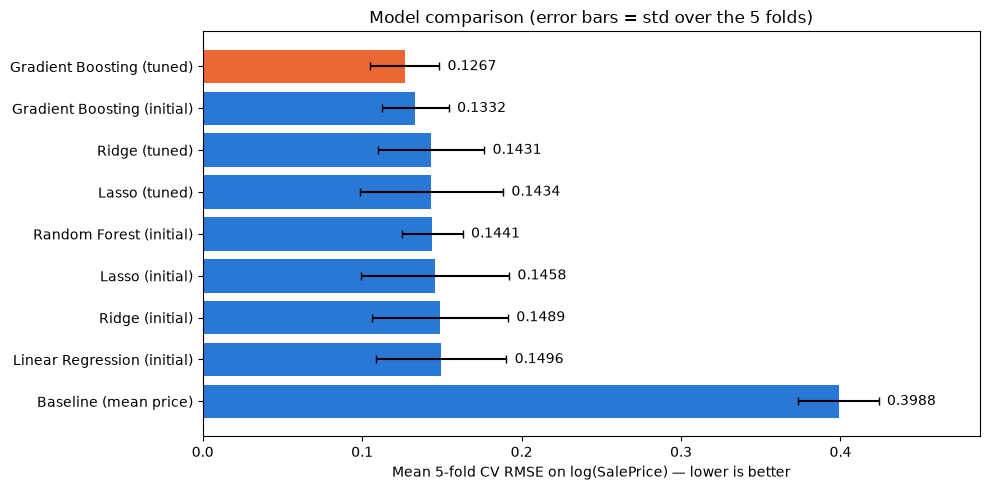

In [16]:
labels = comparison["model"] + " (" + comparison["stage"] + ")"
colors = ["#eb6834"] + ["#2a78d6"] * (len(comparison) - 1)

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(labels, comparison["cv_rmse"], xerr=comparison["cv_std"], color=colors, capsize=3)
ax.bar_label(bars, fmt="%.4f", padding=6)
ax.invert_yaxis()
ax.set_xlabel("Mean 5-fold CV RMSE on log(SalePrice) — lower is better")
ax.set_title("Model comparison (error bars = std over the 5 folds)")
ax.margins(x=0.15)

plt.tight_layout()
fig.savefig(figures_dir / "08_model_comparison.png", dpi=120)
plt.show()

In [17]:
winner = comparison.iloc[0]

print("Best model:", winner["model"], f"({winner['stage']})")
print("Parameters:", winner["params"])
print(f"CV RMSE: {winner['cv_rmse']:.4f} ± {winner['cv_std']:.4f}")

Best model: Gradient Boosting (tuned)
Parameters: n_estimators=1000, learning_rate=0.03, max_depth=4
CV RMSE: 0.1267 ± 0.0217


In [18]:
from sklearn.base import clone

tuned_models = {
    "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=best_ridge_alpha)),
    "Lasso": make_pipeline(StandardScaler(), Lasso(alpha=best_lasso_alpha, max_iter=50000)),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=best_n_estimators,
        learning_rate=best_learning_rate,
        max_depth=best_max_depth,
        subsample=0.8,
        random_state=42,
    ),
}
best_model = tuned_models[winner["model"]]

lasso = clone(tuned_models["Lasso"])
lasso.fit(X_train, y_train)
lasso_coefficients = lasso[-1].coef_
print("Tuned Lasso keeps", (lasso_coefficients != 0).sum(), "of", len(lasso_coefficients), "features")

Tuned Lasso keeps 92 of 303 features


**The best model is the tuned Gradient Boosting (`n_estimators=1000`, `learning_rate=0.03`, `max_depth=4`) with a
CV RMSE of 0.1267 ± 0.0217.**

- It is better than the tuned Lasso (0.1434) in 4 of the 5 folds and better than or equal to the tuned Ridge (0.1431)
  in all 5 folds.
- The biggest difference is in fold 3 (0.165 vs 0.21–0.23). The linear models extrapolate the price of the two huge
  houses (Id 524 and 1299) far too high, while the trees cannot predict above the prices they have seen.
- Without fold 3 the gap is smaller (about 0.117 vs 0.122 for Lasso), so Gradient Boosting is also a bit better on the
  normal houses.
- Lasso keeps 92 of the 303 features, so it is a much simpler model, but its error is higher.

## C5. Error analysis

For the error analysis I use the **out-of-fold predictions** of the best model: every training house is
predicted by a model that did not see it during training.

In [19]:
from sklearn.metrics import r2_score

oof_predictions = np.zeros(len(X_train))

for train_idx, val_idx in cv.split(X_train):
    model = clone(best_model)
    model.fit(X_train.iloc[train_idx], y_train.iloc[train_idx])

    oof_predictions[val_idx] = model.predict(X_train.iloc[val_idx])

print(f"OOF RMSE: {root_mean_squared_error(y_train, oof_predictions):.4f}")
print(f"OOF R²: {r2_score(y_train, oof_predictions):.4f}")

OOF RMSE: 0.1285
OOF R²: 0.8964


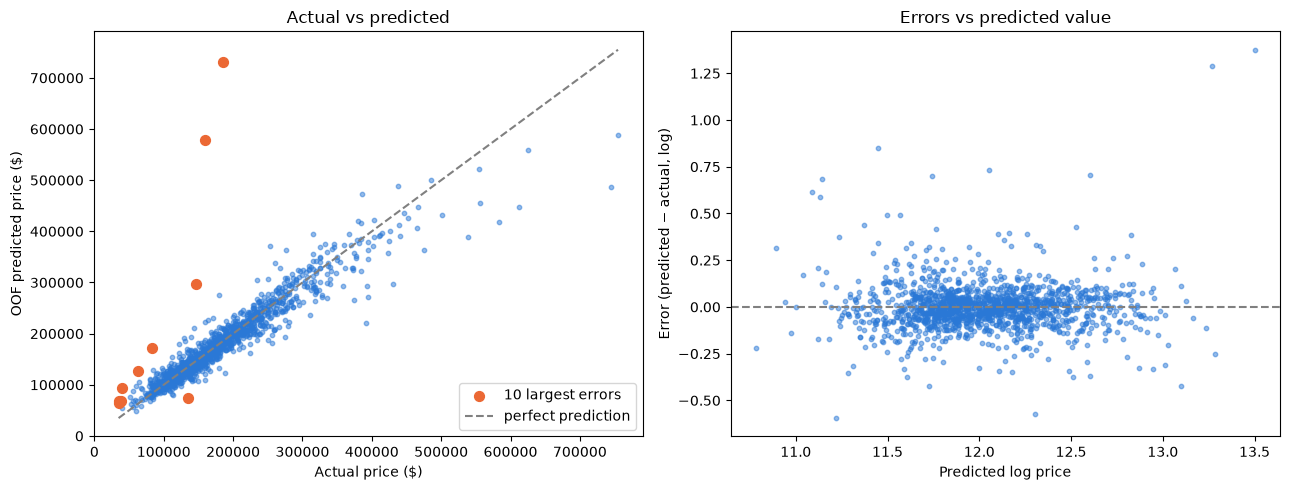

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(errors["actual_price"], errors["predicted_price"], s=10, alpha=0.5, color="#2a78d6")
axes[0].scatter(largest_errors["actual_price"], largest_errors["predicted_price"], s=50, color="#eb6834",
                label="10 largest errors")
limits = [errors["actual_price"].min(), errors["actual_price"].max()]
axes[0].plot(limits, limits, color="gray", linestyle="--", label="perfect prediction")
axes[0].set_xlabel("Actual price ($)")
axes[0].set_ylabel("OOF predicted price ($)")
axes[0].set_title("Actual vs predicted")
axes[0].legend()

axes[1].scatter(oof_predictions, errors["log_error"], s=10, alpha=0.5, color="#2a78d6")
axes[1].axhline(0, color="gray", linestyle="--")
axes[1].set_xlabel("Predicted log price")
axes[1].set_ylabel("Error (predicted − actual, log)")
axes[1].set_title("Errors vs predicted value")

plt.tight_layout()
fig.savefig(figures_dir / "09_error_analysis.png", dpi=120)
plt.show()

In [22]:
def group_rmse(column):
    return (errors.groupby(column)
            .apply(lambda g: pd.Series({"houses": len(g), "rmse": np.sqrt((g["log_error"] ** 2).mean())}),
                   include_groups=False)
            .astype({"houses": int})
            .sort_values("rmse", ascending=False))

group_rmse("SaleCondition").round(4)

,houses,rmse
SaleCondition,,
Family,20,0.2355
Partial,125,0.2223
Alloca,12,0.2202
Abnorml,101,0.2041
AdjLand,4,0.1145
Normal,1198,0.1000


In [23]:
group_rmse("Neighborhood").head(5).round(4)

,houses,rmse
Neighborhood,,
IDOTRR,37,0.2440
Edwards,100,0.2310
StoneBr,25,0.1642
OldTown,113,0.1521
ClearCr,28,0.1401


**Observations**
- The typical error is small: the median error is about 5.5% of the price (≈ \$8,850), and R² on the log scale is 0.90.
- The two largest errors are the huge new houses **Id 524 and 1299** (quality 10, more than 4,500 sq ft, `Partial`
  sales in `Edwards`). They sold for \$160,000–\$185,000, but the model predicts \$580,000–\$730,000, because all
  other houses this large and this good are very expensive.
- 8 of the 10 largest errors are **non-normal sales** (`Partial`, `Family` or `Abnorml`, e.g. foreclosure). For these
  sales the RMSE is about 2 times higher than for `Normal` sales (0.20–0.24 vs 0.10). The price of these sales does not
  depend only on the house, and the model has no information about the circumstances of the sale.
- 9 of the 10 largest errors are **overestimates**. Most of the others are cheap, old houses (for example Id 917:
  built in 1949, quality 2, actual \$35,311, predicted \$65,247). `IDOTRR`, a cheap neighborhood, and `Edwards`
  (where the two huge houses are) have the highest errors (0.24 and 0.23).
- The right plot shows that the errors are centred around 0 for most price levels, but the biggest errors are at low
  prices: the model pulls extreme prices towards the average.

## C6. Kaggle submission

The best model is trained again on **all** training houses (the test set is never used for training),
then it predicts the test houses. Predictions are converted back to dollars with `np.expm1`.

In [24]:
final_model = clone(best_model)
final_model.fit(X_train, y_train)

test_predictions = np.expm1(final_model.predict(X_test))

print("Number of predictions:", len(test_predictions))
print(f"Min: ${test_predictions.min():,.0f}  Median: ${np.median(test_predictions):,.0f}  Max: ${test_predictions.max():,.0f}")
print(f"Training prices: ${train_processed['SalePrice'].min():,.0f} – ${train_processed['SalePrice'].max():,.0f}")

Number of predictions: 1459
Min: $38,841  Median: $156,107  Max: $553,797
Training prices: $34,900 – $755,000


As a safety check, I clip all predictions to the range of the training prices (\$34,900 – \$755,000), so the model
never submits a price far outside the data it has seen. With Gradient Boosting no prediction is outside this range
(the highest is about \$554,000), so the clipping changes nothing. A linear model would need it: the tuned Lasso
predicts about \$1.4 million for test house Id 2550 (5,095 sq ft, quality 10).

In [25]:
low, high = train_processed["SalePrice"].min(), train_processed["SalePrice"].max()
outside = (test_predictions < low) | (test_predictions > high)
print("Predictions outside the training range:", outside.sum(), "-> Id", test_ids[outside].tolist())
test_predictions = np.clip(test_predictions, low, high)

Predictions outside the training range: 0 -> Id []


In [26]:
submission = pd.DataFrame({"Id": test_ids, "SalePrice": test_predictions})
sample = pd.read_csv("../data/raw/sample_submission.csv")

assert list(submission.columns) == list(sample.columns)
assert submission.shape == sample.shape == (1459, 2)
assert (submission["Id"].values == sample["Id"].values).all()
assert submission["SalePrice"].notna().all() and (submission["SalePrice"] > 0).all()

model_name = winner["model"].lower().replace(" ", "_")
submission_path = submissions_dir / f"submission_{model_name}.csv"
submission.to_csv(submission_path, index=False)

print("All checks passed. Saved:", submission_path)
submission.head()

All checks passed. Saved: ../submissions/submission_gradient_boosting.csv


,Id,SalePrice
0,1461,123154.239466
1,1462,153974.256244
2,1463,193132.286182
3,1464,191835.541115
4,1465,180195.150432


### Kaggle score

**Public score: _pending_** — filled in after uploading the submission file to Kaggle.

![Kaggle score](../submissions/kaggle_score.png)

## Conclusion

- The best model is **Gradient Boosting with `n_estimators=1000`, `learning_rate=0.03`, `max_depth=4`**, with a 5-fold
  CV RMSE of **0.1267** on the log price (baseline 0.3988).
- Tuning improved every tuned model. For the linear models the stronger regularization helped, but they still suffer
  from the two huge, cheap houses (Id 524 and 1299), which the trees handle better.
- The largest errors are these two houses, non-normal sales and cheap old houses, which the features cannot fully
  explain.
- Possible improvements: removing the two outliers before training, averaging Lasso and Gradient Boosting predictions,
  log-transforming skewed area features, and trying XGBoost or LightGBM.